# LSST, Roman and Euclid Lensed-AGN Forecasting.
Author: Paras Sharma (github@timedilatesme, paras.sharma@stonybrook.edu)

In [1]:
import os
import numpy as np
from astropy.cosmology import FlatLambdaCDM
from astropy.units import Quantity
from astropy.table import vstack
import matplotlib.pyplot as plt

import pandas as pd
from IPython.display import display

import pickle, gzip
import slsim
import slsim.Pipelines as pipelines
from slsim.Deflectors.DeflectorPopulation.galaxy_deflectors import GalaxyDeflectors
from slsim.Sources.SourcePopulation.point_plus_extended_sources import PointPlusExtendedSources
from slsim.Lenses.LensPopulation.lens_pop import LensPop
from slsim.Sources.SourceCatalogues.QuasarCatalog.quasar_pop import QuasarRate
from slsim.Pipelines import roman_speclite
from astropy.table import Table

from slsim.Deflectors.MassLightConnection.velocity_dispersion import vel_disp_abundance_matching
from utils import extract_lensed_agn_properties, assign_agn_properties, plot_survey_corner, plot_montage, plot_euclid_montage

# filter warnings
import warnings
warnings.filterwarnings("ignore")

%load_ext autoreload
%autoreload 2

In [2]:
DATA_DIR = "./data"
FIGURE_DIR = "./figures"

In [3]:
# -------------------------------------------------------------------
# 1. Setup Configurations & Base Populations
# -------------------------------------------------------------------
cosmo = FlatLambdaCDM(H0=70, Om0=0.3)
path = os.path.dirname(slsim.__file__)
module_path, _ = os.path.split(path)
skypy_config = os.path.join(module_path, "data/SkyPy/euclid-roman-lsst-like.yml")
roman_speclite.configure_roman_filters()

EUCLID_BANDS = ["VIS", "Y", "J", "H"]
ROMAN_BANDS = ["F062", "F087", "F106", "F129", "F158", "F184", "F146", "F213"]
LSST_BANDS = ["u", "g", "r", "i", "z", "y"]
all_bands = LSST_BANDS + ROMAN_BANDS + EUCLID_BANDS

# Define baseline areas and limits for pop generation (we scale sky_area in LensPop later).
# Quasars are drawn over a larger area than galaxies so that fewer lenses share a source quasar.
base_sky_area = Quantity(value=10, unit="deg2")
quasar_sky_area = Quantity(value=100, unit="deg2")
kwargs_deflector_cut = {"band": "i", "band_max": 28, "z_min": 0.01, "z_max": 2.5}
kwargs_source_cut = {"band": "i", "band_max": 28, "z_min": 0.001, "z_max": 5.0}

galaxy_simulation_pipeline = pipelines.SkyPyPipeline(
    skypy_config=skypy_config, sky_area=base_sky_area, filters=None, cosmo=cosmo
)
# QuasarHostMatch needs the morphology: red hosts get M_BH from M-sigma (Kormendy & Ho
# 2013), blue hosts from M-M* (Reines & Volonteri 2015)
galaxy_simulation_pipeline.red_galaxies["galaxy_type"] = "red"
galaxy_simulation_pipeline.blue_galaxies["galaxy_type"] = "blue"
host_galaxy_candidates = vstack(
    [galaxy_simulation_pipeline.red_galaxies, galaxy_simulation_pipeline.blue_galaxies], join_type="exact"
)
# sigma by abundance matching to the SDSS velocity dispersion function (Bernardi et al. 2010) over the area the
# galaxies were drawn on; QuasarRate would otherwise normalise it
# to quasar_sky_area
host_galaxy_candidates["vel_disp"] = vel_disp_abundance_matching(
    host_galaxy_candidates, z_max=0.5, sky_area=base_sky_area, cosmo=cosmo
)(np.log10(host_galaxy_candidates["stellar_mass"]))

# sis_convention=True normalises theta_E as for an SIS. With sis_convention=False
# the Einstein radius is instead solved from the spherical Jeans equation for every
# deflector, which is ~1e4x slower per call (1.1 s vs 0.1 ms) and shifts theta_E by
# ~13% at gamma_pl = 2.078.
lens_galaxies = GalaxyDeflectors(
    red_galaxy_list=galaxy_simulation_pipeline.red_galaxies,
    blue_galaxy_list=galaxy_simulation_pipeline.blue_galaxies,
    kwargs_cut=kwargs_deflector_cut, kwargs_mass2light={}, cosmo=cosmo, sky_area=base_sky_area,
    gamma_pl={"mean": 2.078, "std_dev": 0.16},  # SLACS slope distribution, Auger et al. (2010)
    sis_convention=True,
)

quasar_catalog_path = os.path.join(DATA_DIR, "quasar_source_catalog.fits")
quasar_source = Table.read(quasar_catalog_path) if os.path.exists(quasar_catalog_path) else None
required_columns = [f"ps_mag_{band}" for band in all_bands] + [f"sf_inf_mag_{band}" for band in all_bands] + ["galaxy_type"]
if quasar_source is None or any(column not in quasar_source.colnames for column in required_columns):
    quasar_class = QuasarRate(
        skypy_config=skypy_config, cosmo=cosmo, sky_area=quasar_sky_area, noise=True,
        redshifts=np.linspace(0.001, 5.01, 100), host_galaxy_candidate=host_galaxy_candidates,
        use_qsogen_sed=True, qsogen_bands=all_bands, use_sed_interpolator=True,
    )
    quasar_source = quasar_class.quasar_sample(m_min=15, m_max=30, host_galaxy=True, seed=42)
    # disk orientation (isotropic up to 60 deg), spin 0 and DRW timescale/amplitude (Suberlak et al. 2021);
    # references in utils.py and data/lensed-agn_catalog_data_column_descriptions.txt
    quasar_source = assign_agn_properties(quasar_source, all_bands, seed=11)
    quasar_source.write(quasar_catalog_path, overwrite=True)

source_quasar = PointPlusExtendedSources(
    point_plus_extended_sources_list=quasar_source, cosmo=cosmo, sky_area=quasar_sky_area,
    kwargs_cut=kwargs_source_cut, catalog_type="skypy",
    point_source_type="quasar", extended_source_type="single_sersic", joint_point_source_kwargs={},
)

In [4]:
quasar_source

z,M_i,ps_mag_i,ps_mag_F106,ps_mag_F184,ps_mag_F146,ps_mag_F129,ps_mag_z,ps_mag_F213,ps_mag_g,ps_mag_y,ps_mag_F158,ps_mag_r,ps_mag_F087,ps_mag_F062,M,coeff,ellipticity,physical_size,stellar_mass,angular_size,mag_F062,mag_F087,mag_F106,mag_F129,mag_F158,mag_F184,mag_F146,mag_F213,mag_g,mag_r,mag_i,mag_z,mag_y,vel_disp,black_hole_mass_exponent,eddington_ratio,black_hole_spin,inclination_angle
,,,,,,,,,,,,,,,,,,kpc,,rad,,,,,,,,,,,,,,,,,,
float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64[5],float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
2.6733058817920896,-23.156811947270718,22.699280982619257,22.364136864742733,22.322730653337626,22.37346014285587,22.37473439757231,22.57344440069725,22.4617934029757,22.867293346032298,22.406501929096724,22.425133497690027,22.69371757291421,22.58527227549122,22.735973967611606,-21.666610633635194,0.3618602423107079 .. 0.01070792685926732,0.8092076980337013,4.860693379347154,64603894580.80659,2.9647762025566424e-06,24.56342296739584,24.498945860882383,24.468164667622442,24.219574111531248,23.69845676305344,23.47397906898858,23.933586441817756,23.38239318094139,24.6178096376908,24.5946619078336,24.482887198971344,24.51901892944549,24.514003285364208,126.59017813229916,7.6213623609450805,0.8741094500373524,-0.2486998719150071,41.21937561282868
2.213978540095596,-16.910254266382562,28.50540477574676,28.212431553047086,28.31821372100844,28.241617464289547,28.279428461812586,28.213671540905676,27.686453778895682,28.637397990035044,28.24679765697607,28.195091122291267,28.708691370591552,28.26040187688694,28.632960813317123,-16.7562517770284,0.05089264874948641 .. 0.04685466991009982,0.49190639065435376,1.2956010559334599,978403919.537787,7.606389830494518e-07,29.4610132778539,29.267531063851443,29.004529288864127,28.445814029543747,28.0301293807616,27.855559822248424,28.287364233627386,27.635361055753677,29.588224904117638,29.447684310073456,29.37861037243988,29.27849364923022,29.103878667143306,38.124828285791324,5.338540898607355,0.5308002890044965,-0.5987352734634341,6.573157847218072
1.0334680339650515,-13.65266976021199,29.96749154582042,29.959978883106764,29.9871394010143,29.82677773347934,29.586668953337835,30.08219541499331,29.70718821963535,30.29215600527304,29.862941840103247,29.95884212652093,29.93232340153579,30.04375743645541,29.971187643013685,-14.273744837016723,0.4686391496073827 .. 0.3680302500202436,0.8507392450469822,1.4918913525258082,29975428.84868857,8.962747447725965e-07,29.966292003262886,29.19094185059248,29.004895532884596,28.82767560512226,28.728419579775334,28.641737263100268,28.804345608935414,28.57834142438189,30.39061362236805,29.952177965206644,29.59213711725139,29.1526510564768,29.05560336946101,27.456029145649445,4.714083557915805,0.11106339327364664,-0.9090193354344731,66.68277450955696
1.0333885180302627,-16.146258400373494,27.473775785979488,27.462185942647174,27.48268812110021,27.334237659959143,27.105555680019307,27.571566832845438,27.211494918837097,27.763981448879665,27.367431637303294,27.45932291517244,27.430666663180496,27.537770377296045,27.469587976661856,-17.507680445131342,0.110961143422496 .. 0.06506046038019092,0.1424951880950091,0.9026221763803645,2001243495.1502097,5.423480149887589e-07,26.98025544087504,25.978434229814773,25.636148071554047,25.35724002826558,25.17740744531558,25.01530888135575,25.294771689279052,24.87705099292843,27.475060313955517,26.98941332787433,26.512350377828923,25.945883419121877,25.732154245651202,40.315191275060805,5.4448033267777305,0.2056292607808766,-0.9546124742821899,9.916977544865379
0.626425179895944,-12.607134219613204,29.839860233204522,29.503950091394362,29.657711074301012,29.70853670239985,29.930583392134594,29.985476559027873,29.48282937955767,29.913557621013013,29.887760319756744,29.796349070912576,29.944

In [5]:
# -------------------------------------------------------------------
# 2. Define Specific Survey Parameters (https://roman-docs.stsci.edu/roman-community-defined-surveys)
# -------------------------------------------------------------------
survey_data = {
    "LSST": {
        "name": "LSST",
        "observatory": "LSST",
        "sky_area": Quantity(value=20000, unit="deg2"),
        "kwargs_lens_cuts": {
            "min_image_separation": 0.5,
            "max_image_separation": 4.0,
            "second_brightest_image_cut": {"i": 23.3},
        },
        "sim_bands": ["i", "r", "g"], # Bands to simulate for image montage
        "rgb_bands": ["i", "r", "g"], # RGB mapping for the montage
        "catalog_savepath": os.path.join(DATA_DIR, "lsst_lensed_agn_catalog.fits"),
    },
    "Roman_Medium": {
        "name": "Roman Medium Tier",
        "observatory": "Roman",
        "sky_area": Quantity(value=2415, unit="deg2"),
        "kwargs_lens_cuts": {
            "min_image_separation": 0.2,
            "max_image_separation": 4.0,
            "second_brightest_image_cut": {"F106": 26.5, "F129": 26.4, "F158": 26.4},
        },
        "sim_bands": ["F158", "F129", "F106"],
        "rgb_bands": ["F158", "F129", "F106"],
        "catalog_savepath": os.path.join(DATA_DIR, "roman_medium_lensed_agn_catalog.fits"),
    },
    "Roman_Medium_2029": {
        "name": "Roman Medium Tier (2029)",
        "observatory": "Roman",
        "sky_area": Quantity(value=500, unit="deg2"), # Only 500 sq deg completed by 2029
        "kwargs_lens_cuts": {
            "min_image_separation": 0.2,
            "max_image_separation": 4.0,
            "second_brightest_image_cut": {"F106": 26.5, "F129": 26.4, "F158": 26.4},
        },
        "sim_bands": ["F158", "F129", "F106"],
        "rgb_bands": ["F158", "F129", "F106"],
        "catalog_savepath": os.path.join(DATA_DIR, "roman_medium_2029_lensed_agn_catalog.fits"),
    },
    "Roman_Wide": {
        "name": "Roman Wide Tier",
        "observatory": "Roman",
        "sky_area": Quantity(value=2702, unit="deg2"),
        "kwargs_lens_cuts": {
            "min_image_separation": 0.2,
            "max_image_separation": 4.0,
            "second_brightest_image_cut": {"F158": 26.2},
        },
        "sim_bands": ["F158", "F158", "F158"], # Single band defaults to grayscale
        "rgb_bands": ["F158", "F158", "F158"], 
        "catalog_savepath": os.path.join(DATA_DIR, "roman_wide_lensed_agn_catalog.fits")
    },
    "Roman_NANCY": {
        "name": "Roman NANCY",
        "observatory": "Roman",
        "sky_area": Quantity(value=1000, unit="deg2"),
        "kwargs_lens_cuts": {
            "min_image_separation": 0.2,
            "max_image_separation": 4.0,
            "second_brightest_image_cut": {"F158": 25.5},
        },
        "sim_bands": ["F158", "F158", "F158"], # Updated to single band (F158 only)
        "rgb_bands": ["F158", "F158", "F158"],
        "catalog_savepath": os.path.join(DATA_DIR, "roman_nancy_lensed_agn_catalog.fits")
    },
    "Euclid_Wide": {
        "name": "Euclid Wide",
        "observatory": "Euclid",
        "sky_area": Quantity(value=14500, unit="deg2"),
        "kwargs_lens_cuts": {
            "min_image_separation": 0.2,
            "max_image_separation": 4.0,
            "second_brightest_image_cut": {"VIS": 26.2},  # VIS 5-sigma depth
        },
        "catalog_savepath": os.path.join(DATA_DIR, "euclid_wide_lensed_agn_catalog.fits"),
    },
}

In [6]:
# -------------------------------------------------------------------
# 3. Simulate Populations & Extract Tables
# -------------------------------------------------------------------
for survey_key, data in survey_data.items():
    print(f"Simulating {data['name']} ...")
    
    lens_pop = LensPop(
        deflector_population=lens_galaxies,
        source_population=source_quasar,
        cosmo=cosmo,
        sky_area=data["sky_area"]
    )
    
    # Draw population and store objects directly in dictionary
    population = lens_pop.draw_population(speed_factor=10000, kwargs_lens_cuts=data["kwargs_lens_cuts"])
    data["lens_objects"] = population
    
    # Extract properties into Astropy Table (on all cores)
    catalog = extract_lensed_agn_properties(population, all_bands=all_bands, max_num_images=5, n_jobs=-1)
    data["catalog"] = catalog
    
    num_quads = np.sum(catalog['num_images'] == 4)
    num_doubles = np.sum(catalog['num_images'] == 2)
    print(f"  -> Found {len(catalog)} lenses (Quads: {num_quads}, Doubles: {num_doubles})")
    
    # Save to FITS
    if data.get("catalog_savepath"):
        try:
            catalog_path = data["catalog_savepath"]
            catalog.write(catalog_path, format='fits', overwrite=True)
            
            lens_objects_path = data["catalog_savepath"].replace(".fits", "_lens_objects.pkl.gz")
            with gzip.open(lens_objects_path, 'wb') as f:
                pickle.dump(data["lens_objects"], f)
            print(f"  -> Saved catalog to {data['catalog_savepath']}\n")
            print(f"  -> Saved lens objects to {lens_objects_path}\n")
        except Exception as e:
            print(f"  -> Error saving catalog/lens objects for {survey_key}: {e}\n")

Simulating LSST ...
  -> Found 2340 lenses (Quads: 264, Doubles: 2000)
  -> Saved catalog to ./data/lsst_lensed_agn_catalog.fits

  -> Saved lens objects to ./data/lsst_lensed_agn_catalog_lens_objects.pkl.gz

Simulating Roman Medium Tier ...
  -> Found 2037 lenses (Quads: 157, Doubles: 1826)
  -> Saved catalog to ./data/roman_medium_lensed_agn_catalog.fits

  -> Saved lens objects to ./data/roman_medium_lensed_agn_catalog_lens_objects.pkl.gz

Simulating Roman Medium Tier (2029) ...
  -> Found 425 lenses (Quads: 28, Doubles: 384)
  -> Saved catalog to ./data/roman_medium_2029_lensed_agn_catalog.fits

  -> Saved lens objects to ./data/roman_medium_2029_lensed_agn_catalog_lens_objects.pkl.gz

Simulating Roman Wide Tier ...
  -> Found 2300 lenses (Quads: 195, Doubles: 2038)
  -> Saved catalog to ./data/roman_wide_lensed_agn_catalog.fits

  -> Saved lens objects to ./data/roman_wide_lensed_agn_catalog_lens_objects.pkl.gz

Simulating Roman NANCY ...
  -> Found 646 lenses (Quads: 64, Doubles:

In [ ]:
# Euclid Wide sub-sample whose second-brightest image is also above the NISP 5-sigma depth in Y, J and H
NISP_DEPTH = 24.5
wide = survey_data["Euclid_Wide"]
nisp_detected = np.all(
    [wide["catalog"][f"second_brightest_image_ps_mag_{band}"] < NISP_DEPTH for band in ["Y", "J", "H"]], axis=0
)
survey_data["Euclid_Wide_NISP"] = {
    "name": "Euclid Wide (VIS+NISP)",
    "sky_area": wide["sky_area"],
    "kwargs_lens_cuts": {
        **wide["kwargs_lens_cuts"],
        "second_brightest_image_cut": {"VIS": 26.2, "Y": NISP_DEPTH, "J": NISP_DEPTH, "H": NISP_DEPTH},
    },
    "catalog": wide["catalog"][nisp_detected],
    "lens_objects": [lens for lens, keep in zip(wide["lens_objects"], nisp_detected) if keep],
}

In [7]:
# -------------------------------------------------------------------
# Table to Summarize Key Numbers
# -------------------------------------------------------------------

# Create a list to hold the row dictionaries
summary_rows = []

for survey_key, data in survey_data.items():
    catalog = data.get("catalog")
    
    # Skip if no catalog was generated
    if catalog is None or len(catalog) == 0:
        continue
        
    # Calculate statistics
    num_quads = np.sum(catalog['num_images'] == 4)
    num_doubles = np.sum(catalog['num_images'] == 2)
    total_lenses = num_quads + num_doubles
    quad_frac = num_quads / total_lenses if total_lenses > 0 else 0.0
    
    # Format cuts
    area = data["sky_area"].value
    cuts = data["kwargs_lens_cuts"]
    min_sep = cuts.get("min_image_separation", "N/A")
    max_sep = cuts.get("max_image_separation", "N/A")
    
    mag_cuts = cuts.get("second_brightest_image_cut", {})
    mag_cut_str = ", ".join([f"{band} < {limit}" for band, limit in mag_cuts.items()])
    
    # Append to our list
    summary_rows.append({
        "Survey": data["name"],
        "Sky Area (deg²)": f"{area:,.0f}",
        "Total Lensed-AGN": f"{total_lenses:,}",
        "Doubles": f"{num_doubles:,}",
        "Quads": f"{num_quads:,}",
        "Quad Fraction": f"{quad_frac:.1%}",
        "Image Sep Cuts (\")": f"{min_sep} - {max_sep}",
        "Mag Cuts (2nd Brightest Image)": mag_cut_str
    })

# Convert to a Pandas DataFrame
summary_df = pd.DataFrame(summary_rows)

# Set the 'Survey' column as the index for a cleaner look
summary_df.set_index("Survey", inplace=True)

# Display the styled table
display(summary_df)

,Sky Area (deg²),Total Lensed-AGN,Doubles,Quads,Quad Fraction,"Image Sep Cuts ("")",Mag Cuts (2nd Brightest Image)
Survey,,,,,,,
LSST,"20,000","2,264","2,000",264,11.7%,0.5 - 4.0,i < 23.3
Roman Medium Tier,"2,415","1,983","1,826",157,7.9%,0.2 - 4.0,"F106 < 26.5, F129 < 26.4, F158 < 26.4"
Roman Medium Tier (2029),500,412,384,28,6.8%,0.2 - 4.0,"F106 < 26.5, F129 < 26.4, F158 < 26.4"
Roman Wide Tier,"2,702","2,233","2,038",195,8.7%,0.2 - 4.0,F158 < 26.2
Roman NANCY,"1,000",628,564,64,10.2%,0.2 - 4.0,F158 < 25.5


Saved figure to: ./figures/corner_roman_nancy_vs_medium2029.png


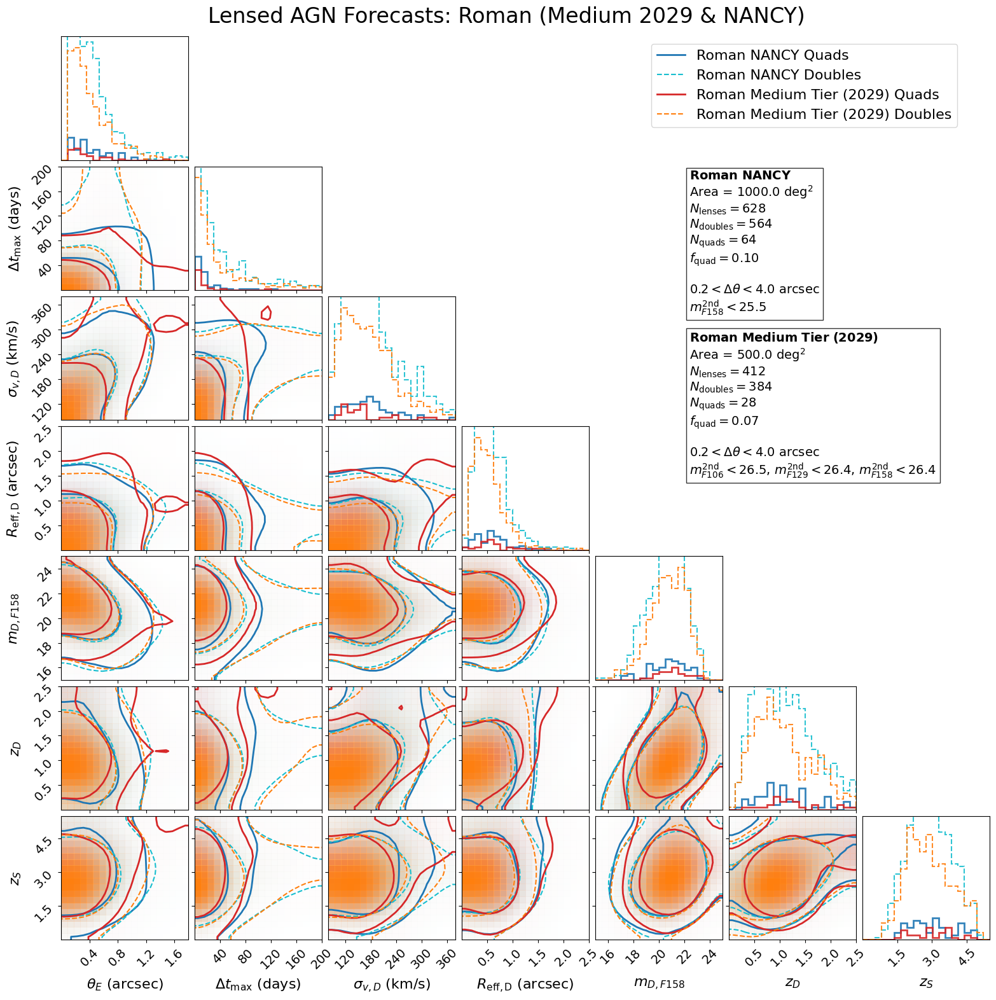

Saved figure to: ./figures/corner_lsst_vs_roman_med_wide_combined.png


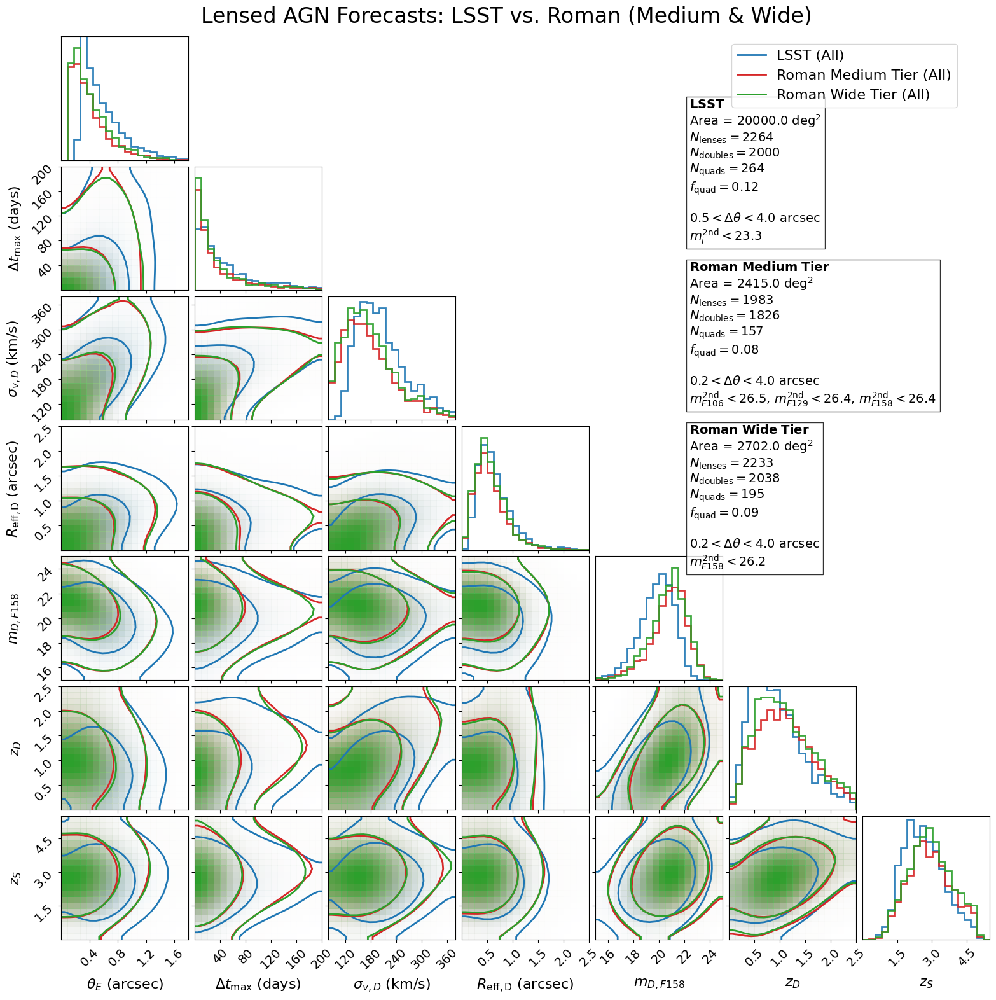

Saved figure to: ./figures/corner_roman_med_vs_wide.png


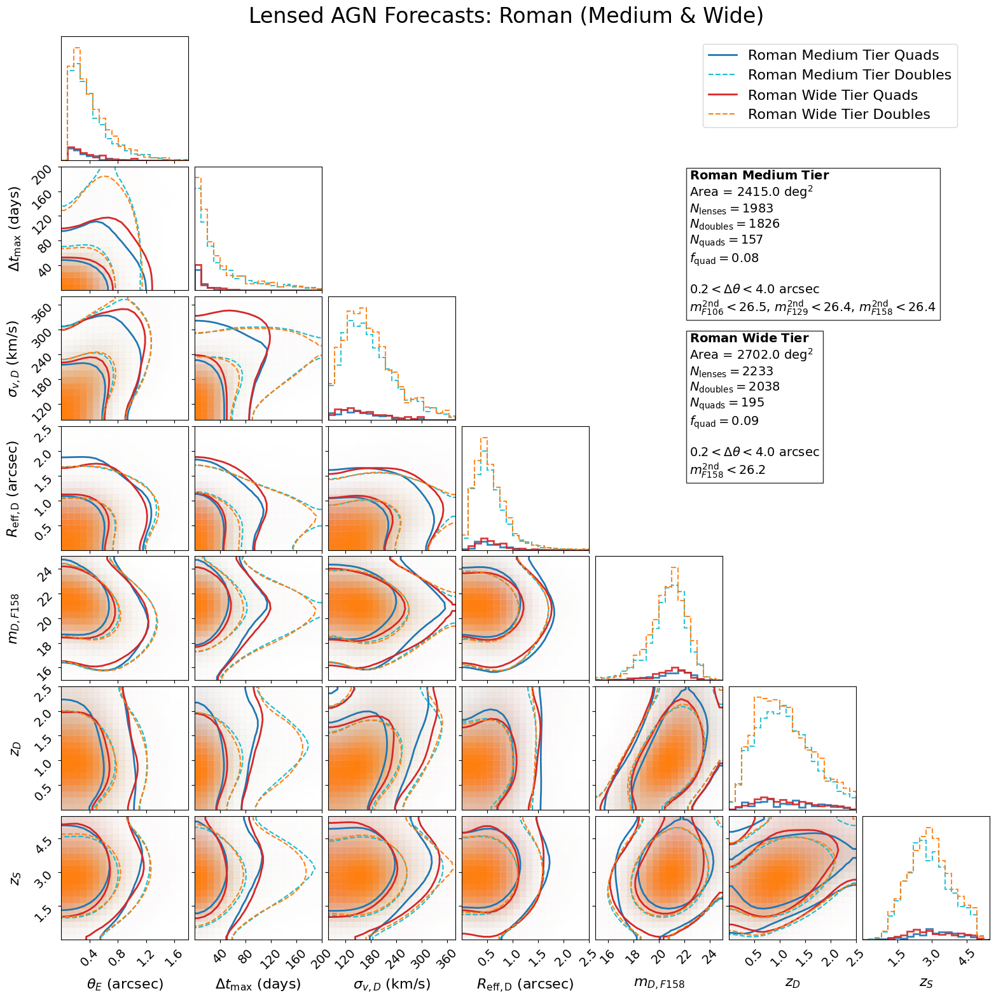

In [8]:
# -------------------------------------------------------------------
# Common Setup for All Corner Plots
# -------------------------------------------------------------------
plot_params = ['theta_E_arcsec', 'max_time_delay_days', 'deflector_velocity_dispersion', 'deflector_light_R_eff_arcsec', 'deflector_mag_F158', 'z_D', 'z_S']
latex_labels = [r'$\theta_E$ (arcsec)', r'$\Delta t_{\max}$ (days)', r'$\sigma_{v, D}$ (km/s)', r'$R_{\rm eff, D}$ (arcsec)', r'$m_{D, F158}$', r'$z_D$', r'$z_S$']

range_vals = {
    'theta_E_arcsec': (0, 1.8),
    'deflector_velocity_dispersion': (80, 380),
    'max_time_delay_days': (0, 200),
    'deflector_light_R_eff_arcsec': (0, 2.5),
    'deflector_mag_F158': (15, 25),
    'z_D': (0, 2.5),
    'z_S': (0, 5.5),
}


# -------------------------------------------------------------------
# Scenario 1: Roman NANCY & Roman Medium (2029) - Separated Quads/Doubles
# -------------------------------------------------------------------
fig1 = plot_survey_corner(
    survey_data=survey_data,
    keys_to_plot=["Roman_NANCY", "Roman_Medium_2029"],
    params=plot_params,
    latex_labels=latex_labels,
    range_vals=range_vals,
    color_map={
        "Roman_Medium_2029": {"quads": "tab:red", "doubles": "tab:orange"},
        "Roman_NANCY": {"quads": "tab:blue", "doubles": "tab:cyan"},
    },
    title="Lensed AGN Forecasts: Roman (Medium 2029 & NANCY)",
    figsize=(16, 16),
    text_x=0.68, 
    text_y_start=0.68, 
    text_y_step=0.16,
    smooth=3,
    separate_quads_doubles=True,
    save_path=os.path.join(FIGURE_DIR, "corner_roman_nancy_vs_medium2029.png")
)
plt.show()


# -------------------------------------------------------------------
# Scenario 2: LSST, Roman Medium, & Roman Wide - Combined Lenses (All)
# -------------------------------------------------------------------
fig2 = plot_survey_corner(
    survey_data=survey_data,
    keys_to_plot=["LSST", "Roman_Medium", "Roman_Wide"],
    params=plot_params,
    latex_labels=latex_labels,
    range_vals=range_vals,
    color_map={
        # Using the "all" key since separate_quads_doubles=False
        "LSST": {"all": "tab:blue"},
        "Roman_Medium": {"all": "tab:red"},
        "Roman_Wide": {"all": "tab:green"},
    },
    title="Lensed AGN Forecasts: LSST vs. Roman (Medium & Wide)",
    figsize=(16, 16),
    text_x=0.68, 
    text_y_start=0.75, # Moved up slightly to fit 3 boxes 
    text_y_step=0.16,
    smooth=3,
    separate_quads_doubles=False,
    save_path=os.path.join(FIGURE_DIR, "corner_lsst_vs_roman_med_wide_combined.png")
)
plt.show()


# -------------------------------------------------------------------
# Scenario 3: Roman Medium & Roman Wide - Separated Quads/Doubles
# -------------------------------------------------------------------
fig3 = plot_survey_corner(
    survey_data=survey_data,
    keys_to_plot=["Roman_Medium", "Roman_Wide"],
    params=plot_params,
    latex_labels=latex_labels,
    range_vals=range_vals,
    color_map={
        "Roman_Medium": {"quads": "tab:blue", "doubles": "tab:cyan"},
        "Roman_Wide": {"quads": "tab:red", "doubles": "tab:orange"},
    },
    title="Lensed AGN Forecasts: Roman (Medium & Wide)",
    figsize=(16, 16),
    text_x=0.68, 
    text_y_start=0.68, 
    text_y_step=0.16,
    smooth=3, 
    smooth1d=None,
    separate_quads_doubles=True,
    save_path=os.path.join(FIGURE_DIR, "corner_roman_med_vs_wide.png")
)
plt.show()


# -------------------------------------------------------------------
# Scenario 4: LSST, Roman Wide & Euclid Wide - Combined Lenses (All)
# -------------------------------------------------------------------
fig4 = plot_survey_corner(
    survey_data=survey_data,
    keys_to_plot=["LSST", "Roman_Wide", "Euclid_Wide"],
    params=plot_params,
    latex_labels=latex_labels,
    range_vals=range_vals,
    color_map={
        "LSST": {"all": "tab:blue"},
        "Roman_Wide": {"all": "tab:green"},
        "Euclid_Wide": {"all": "tab:purple"},
    },
    title="Lensed AGN Forecasts: LSST vs. Roman Wide vs. Euclid Wide",
    figsize=(16, 16),
    text_x=0.68,
    text_y_start=0.75,
    text_y_step=0.16,
    smooth=3,
    separate_quads_doubles=False,
    save_path=os.path.join(FIGURE_DIR, "corner_lsst_vs_roman_wide_vs_euclid_wide.png")
)
plt.show()


# -------------------------------------------------------------------
# Scenario 5: Euclid Wide & its NISP-detected sub-sample - Separated Quads/Doubles
# -------------------------------------------------------------------
euclid_params = [p if p != "deflector_mag_F158" else "deflector_mag_VIS" for p in plot_params]
euclid_labels = [l if l != r'$m_{D, F158}$' else r'$m_{D, \rm VIS}$' for l in latex_labels]
fig5 = plot_survey_corner(
    survey_data=survey_data,
    keys_to_plot=["Euclid_Wide", "Euclid_Wide_NISP"],
    params=euclid_params,
    latex_labels=euclid_labels,
    range_vals={**range_vals, "deflector_mag_VIS": (15, 25)},
    color_map={
        "Euclid_Wide": {"quads": "tab:blue", "doubles": "tab:cyan"},
        "Euclid_Wide_NISP": {"quads": "tab:red", "doubles": "tab:orange"},
    },
    title="Lensed AGN Forecast: Euclid Wide Survey",
    figsize=(16, 16),
    text_x=0.68,
    text_y_start=0.72,
    text_y_step=0.18,
    smooth=3,
    separate_quads_doubles=True,
    save_path=os.path.join(FIGURE_DIR, "corner_euclid_wide.png")
)
plt.show()

Plotting montage for LSST...


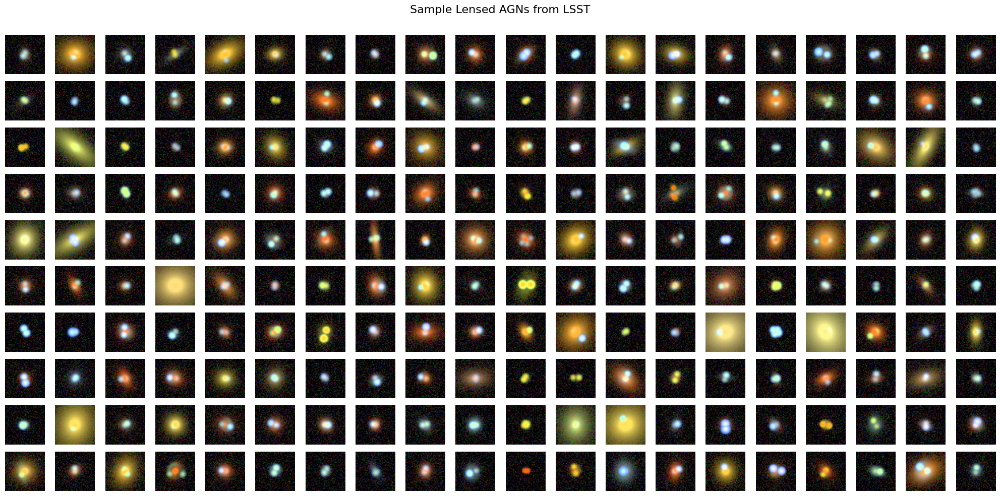

Plotting montage for Roman Medium Tier...


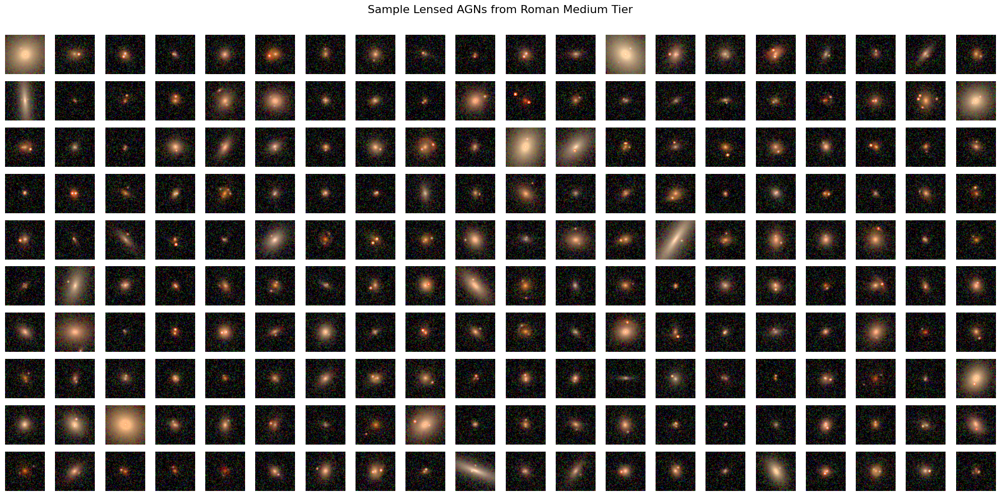

Plotting montage for Roman Medium Tier (2029)...


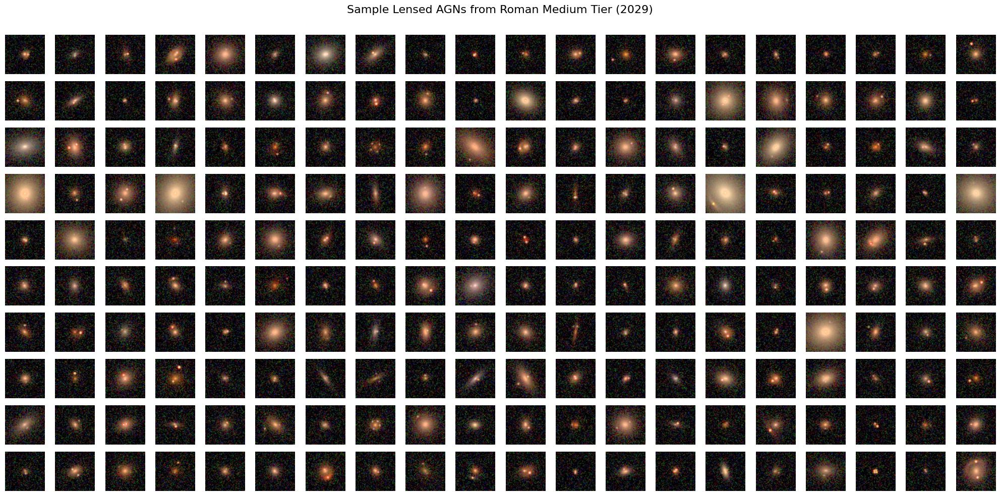

Plotting montage for Roman Wide Tier...


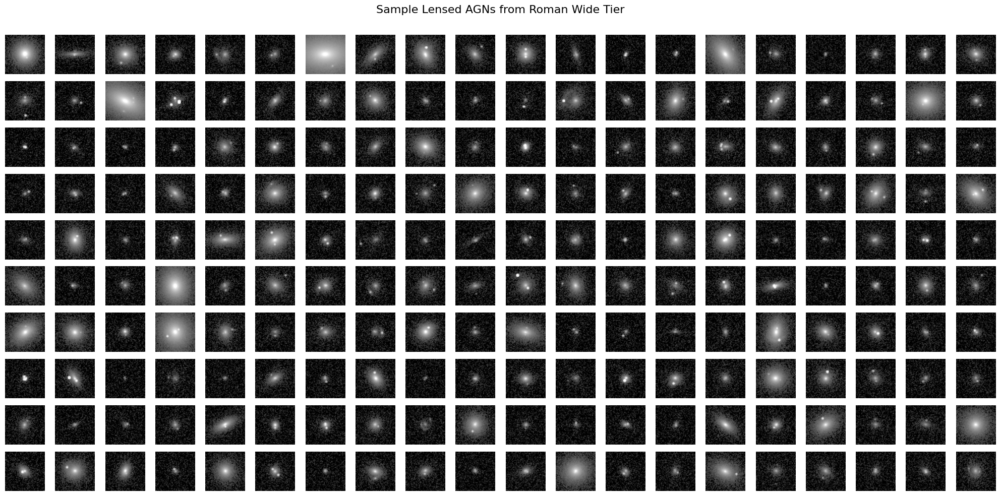

Plotting montage for Roman NANCY...


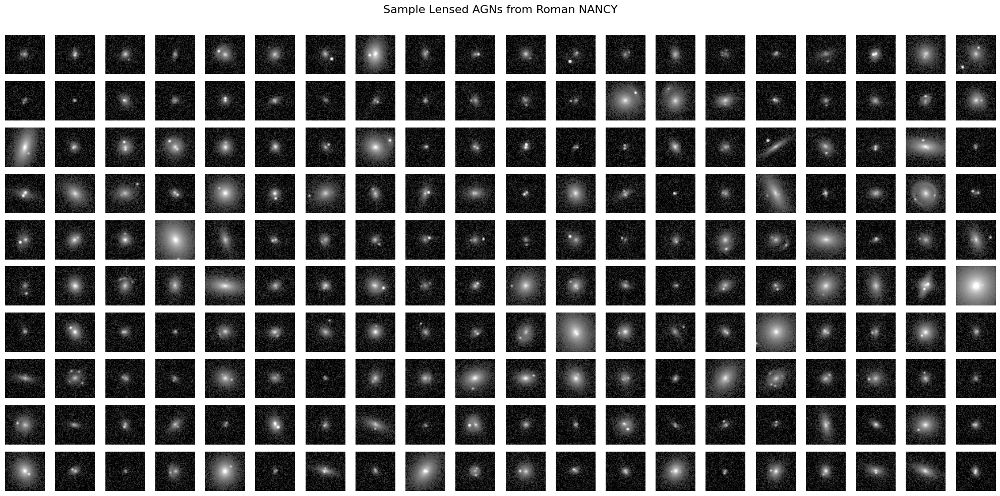

In [9]:
# -------------------------------------------------------------------
# 5. Plot Image Montages for Each Survey
# -------------------------------------------------------------------
for survey_key, data in survey_data.items():
    if "observatory" not in data:  # derived sub-samples
        continue
    population = data["lens_objects"]
    
    if len(population) == 0:
        print(f"No lenses found for {data['name']}, skipping montage.")
        continue
        
    print(f"Plotting montage for {data['name']}...")

    if data["observatory"] == "Euclid":
        fig = plot_euclid_montage(
            lenses=population,
            number_to_plot=min(100, len(population)),
            num_cols=10, num_pix_vis=50,
            colour="VIS_WEIGHTED_Y_J_H", stretch="arcsinh",
            plot_title=f"Sample Lensed AGNs from {data['name']} (VIS + Y/J/H)",
        )
        if fig is not None:
            fig.savefig(f"{FIGURE_DIR}/montage_{data['name']}.png", dpi=300, bbox_inches='tight')
            plt.show()
        continue
    
    fig = plot_montage(
        lenses=population, 
        number_to_plot=min(200, len(population)),
        num_cols=20,
        bands=data["sim_bands"],
        rgb_bands=data["rgb_bands"],
        rgb_stretch=0.5,
        num_pix=50,
        plot_title=f"Sample Lensed AGNs from {data['name']}",
        # random_seed=42,
        observatory=data["observatory"] # Dynamically route to LSST or Roman
    )

    # save the figure
    if fig is not None:
        fig.savefig(f"{FIGURE_DIR}/montage_{data['name']}.png", dpi=300, bbox_inches='tight')
        plt.show()